<a href="https://colab.research.google.com/github/arxsyy/MachineLearning_2026/blob/main/JS08_Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
# 2. Membaca Dataset

df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan 5 data pertama
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
# 3. Melihat Informasi Dataset

print("Jumlah baris dan kolom:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Missing Value:")
print(df.isnull().sum())

Jumlah baris dan kolom: (660, 7)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah Missing Value:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


In [4]:
# 4. Memilih Variabel untuk Clustering

features = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X = df[features]

# Menampilkan data yang digunakan
X.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


In [5]:
# 5. Melakukan Standardisasi Data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Menampilkan hasil standardisasi
print("Hasil Standardisasi:")
print(X_scaled[:5])

Hasil Standardisasi:
[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


In [6]:
# 6. Eksperimen Jumlah Cluster

hasil_cluster = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_scaled)

    sil_score = silhouette_score(X_scaled, labels)
    dbi_score = davies_bouldin_score(X_scaled, labels)

    hasil_cluster.append({
        'Jumlah Cluster': k,
        'Silhouette Score': sil_score,
        'DBI': dbi_score
    })

hasil_df = pd.DataFrame(hasil_cluster)

hasil_df

,Jumlah Cluster,Silhouette Score,DBI
0,2,0.417704,0.932640
1,3,0.514764,0.680960
2,4,0.348082,1.149303
3,5,0.256918,1.385112
4,6,0.226778,1.410876
5,7,0.216297,1.439434
6,8,0.218695,1.448888
7,9,0.195271,1.546620
8,10,0.193142,1.553695


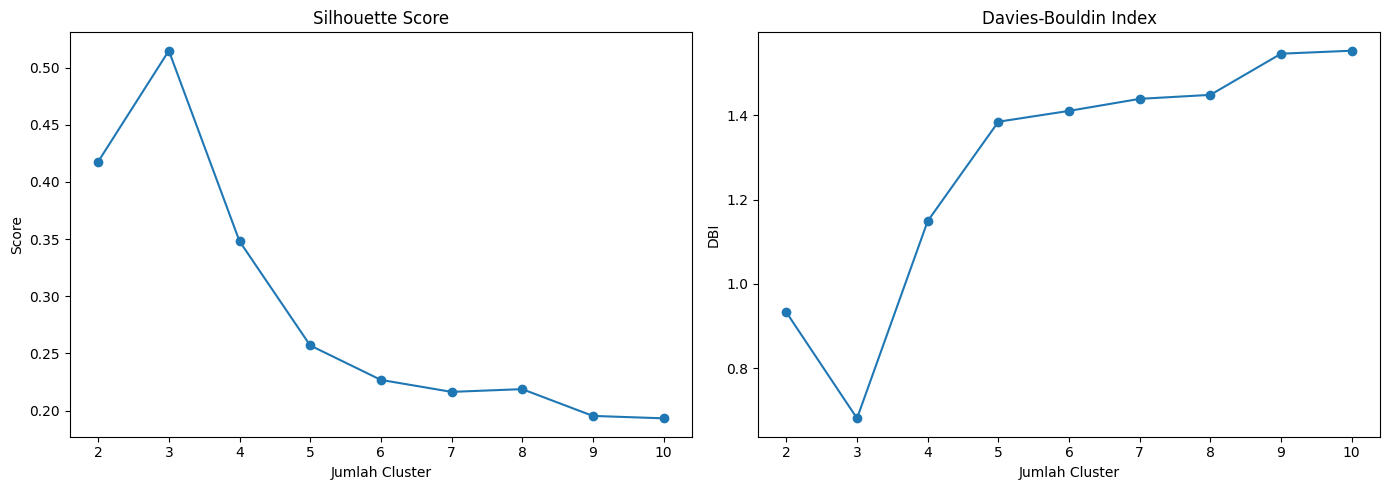

In [7]:
# 7. Visualisasi Evaluasi Jumlah Cluster

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    hasil_df['Jumlah Cluster'],
    hasil_df['Silhouette Score'],
    marker='o'
)
axes[0].set_title('Silhouette Score')
axes[0].set_xlabel('Jumlah Cluster')
axes[0].set_ylabel('Score')

axes[1].plot(
    hasil_df['Jumlah Cluster'],
    hasil_df['DBI'],
    marker='o'
)
axes[1].set_title('Davies-Bouldin Index')
axes[1].set_xlabel('Jumlah Cluster')
axes[1].set_ylabel('DBI')

plt.tight_layout()
plt.show()

In [8]:
# 8. Membuat Model Agglomerative Clustering

model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = model.fit_predict(X_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = labels

# Menampilkan hasil clustering
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,Cluster
0,1,87073,100000,2,1,1,0,0
1,2,38414,50000,3,0,10,9,1
2,3,17341,50000,7,1,3,4,0
3,4,40496,30000,5,1,1,4,0
4,5,47437,100000,6,0,12,3,2


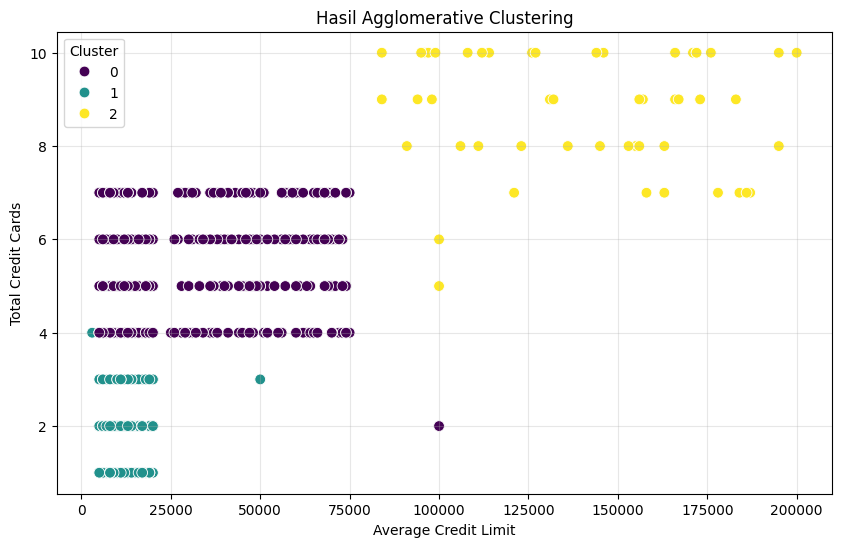

In [9]:
# 9. Scatterplot Hasil Agglomerative Clustering

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Hasil Agglomerative Clustering')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

In [10]:
# 10. Evaluasi Model Clustering

sil_score = silhouette_score(X_scaled, labels)
dbi_score = davies_bouldin_score(X_scaled, labels)

print("Hasil Evaluasi Agglomerative Clustering")
print("Jumlah Cluster:", len(np.unique(labels)))
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(dbi_score, 4))

Hasil Evaluasi Agglomerative Clustering
Jumlah Cluster: 3
Silhouette Score: 0.5148
Davies-Bouldin Index: 0.681


In [11]:
# 11. Menghitung Jumlah Anggota Setiap Cluster

print("Jumlah Anggota Setiap Cluster:")
print(df['Cluster'].value_counts().sort_index())

Jumlah Anggota Setiap Cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


In [12]:
# 12. Analisis Karakteristik Setiap Cluster

cluster_summary = df.groupby('Cluster')[features].mean().round(2)

cluster_summary

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
0,33851.95,5.52,3.49,0.98,1.99
1,12151.11,2.42,0.94,3.55,6.86
2,141040.00,8.74,0.60,10.90,1.08


Berdasarkan proses clustering menggunakan algoritma Agglomerative Clustering, diperoleh 3 kelompok pelanggan dari total 660 data. Model menghasilkan nilai Silhouette Score sebesar 0,5148 dan Davies-Bouldin Index sebesar 0,6810. Berdasarkan pengujian jumlah cluster dari 2 hingga 10, penggunaan 3 cluster memberikan nilai Silhouette Score tertinggi dan DBI terendah. Dengan demikian, 3 cluster dipilih sebagai jumlah pengelompokan terbaik dari percobaan yang dilakukan.